Please upload your Cowrie JSON log file.


Saving cowrie.json (1).2026-11-02 to cowrie.json (1) (7).2026-11-02
Uploaded file: cowrie.json (1) (7).2026-11-02

JSON successfully loaded
Total events: 50
Unique sessions: 2

EVENT SUMMARY


,Event,Count
0,cowrie.command.input,27
1,cowrie.command.failed,7
2,cowrie.session.connect,2
3,cowrie.client.version,2
4,cowrie.session.params,2
5,cowrie.client.kex,2
6,cowrie.client.size,2
7,cowrie.login.success,2
8,cowrie.login.failed,1
9,cowrie.session.file_download,1



COMMANDS FOUND: 27

FAILED COMMAND EVENTS: 7

SESSION-WISE ATTACK DETECTION


,session,attacker_ip,total_events,total_commands,failed_commands,successful_logins,failed_logins,download_events,detected_attack_patterns
0,9bfdbc02c401,192.168.1.27,30,14,6,1,1,1,"Download_Attempt, Download_Confirmed_By_Cowrie_Event, Failed_Login_Observed, Filesystem_Exploration, Network_Reconna..."
1,b1366d0e6d73,192.168.1.27,20,13,1,1,0,0,"Configuration_Discovery, Filesystem_Exploration, Network_Reconnaissance, Successful_Login_Observed, System_Reconnais..."



ATTACK PATTERN SUMMARY


,Attack_Pattern,Count
0,Filesystem_Exploration,10
1,System_Reconnaissance,7
2,Network_Reconnaissance,7
3,Password_File_Access_Attempt,2
4,User_Enumeration,2
5,Download_Attempt,1
6,Configuration_Discovery,1


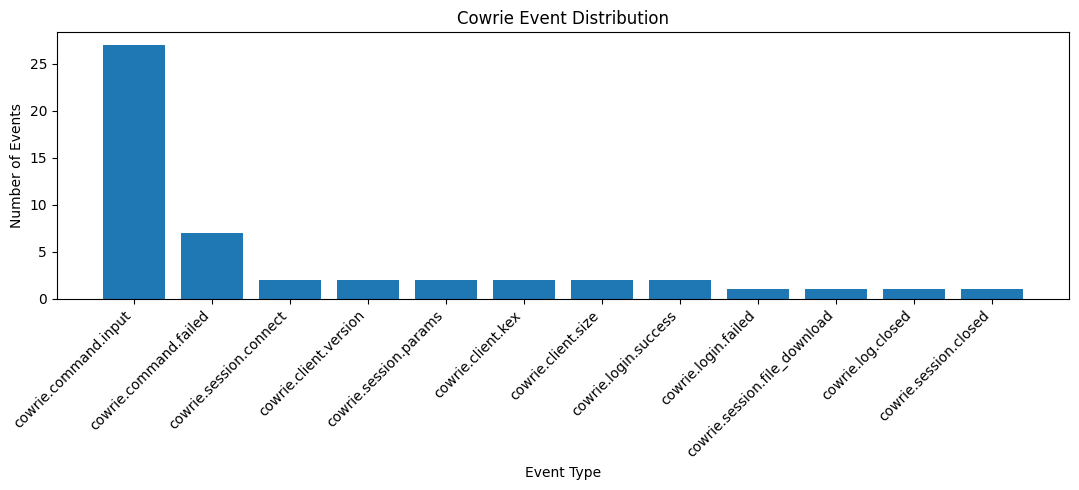

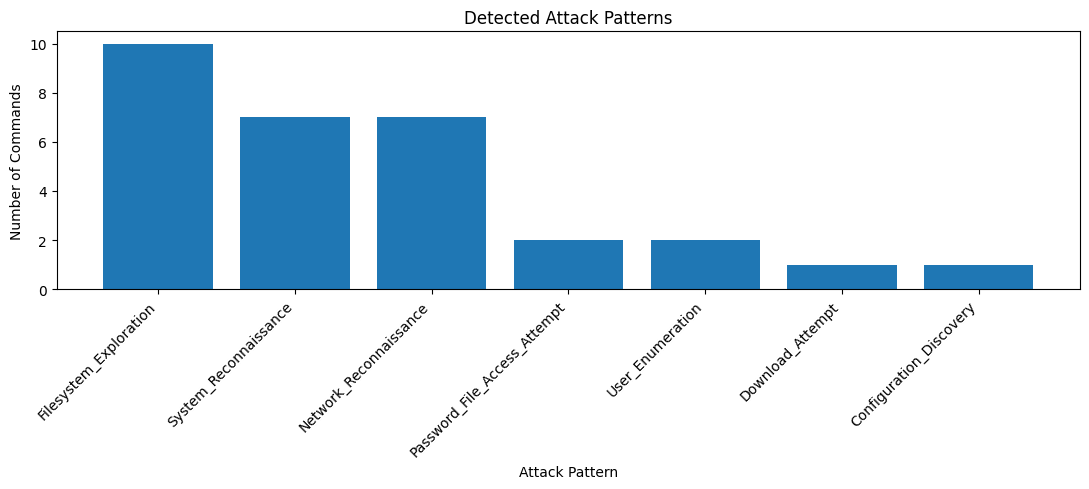


HTML REPORT GENERATED: Cowrie_Attack_Detection_Reports/cowrie_detection_report.html

COWRIE ATTACK DETECTION COMPLETED
HTML report: Cowrie_Attack_Detection_Reports/cowrie_detection_report.html
Main CSV report: Cowrie_Attack_Detection_Reports/cowrie_detection_report.csv
Complete ZIP: Cowrie_Complete_Detection_Reports.zip

Starting report downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All download requests have been sent.
If Chrome blocks multiple downloads, allow them and retry.


In [9]:

# ================================================================
# COWRIE HONEYPOT - AUTOMATIC ATTACK DETECTION & REPORT GENERATION
# Upload JSON -> Detect -> HTML Report -> CSV Reports -> Downloads
# ================================================================

import os
import re
import json
import zipfile
import time
import base64
import io
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime
from google.colab import files
from IPython.display import display, HTML

# ================================================================
# 1. UPLOAD JSON FILE
# ================================================================

print("Please upload your Cowrie JSON log file.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

filename = next(iter(uploaded))

print("Uploaded file:", filename)

# ================================================================
# 2. READ JSON LOGS
# ================================================================

records = []

with open(filename, "r", encoding="utf-8") as f:
    for line in f:
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            continue

raw_df = pd.DataFrame(records)

if raw_df.empty:
    raise ValueError("No valid JSON records found.")

required_columns = ["eventid", "session", "src_ip"]

for col in required_columns:
    if col not in raw_df.columns:
        raw_df[col] = "Unknown"

raw_df["eventid"] = raw_df["eventid"].fillna("Unknown")
raw_df["session"] = raw_df["session"].fillna("Unknown")
raw_df["src_ip"] = raw_df["src_ip"].fillna("Unknown")

print("\nJSON successfully loaded")
print("Total events:", len(raw_df))
print("Unique sessions:", raw_df["session"].nunique())

# ================================================================
# 3. EVENT SUMMARY
# ================================================================

event_summary = (
    raw_df["eventid"]
    .value_counts()
    .rename_axis("Event")
    .reset_index(name="Count")
)

print("\nEVENT SUMMARY")
display(event_summary)

# ================================================================
# 4. EXTRACT COMMANDS
# ================================================================

command_events = raw_df[
    raw_df["eventid"].astype(str).str.contains(
        "command.input", case=False, na=False
    )
].copy()

if "input" not in command_events.columns:
    command_events["input"] = ""

command_events["command"] = (
    command_events["input"].fillna("").astype(str).str.strip()
)

print("\nCOMMANDS FOUND:", len(command_events))

# ================================================================
# 5. ATTACK DETECTION RULES
# ================================================================

ATTACK_RULES = {
    "Network_Reconnaissance": [
        r"^ifconfig\b",
        r"^ip\s+(?:a|addr|address)\b",
        r"^netstat\b",
        r"^arp\s+-a\b"
    ],

    "System_Reconnaissance": [
        r"^uname\b",
        r"^hostname\b",
        r"^whoami\b",
        r"^who\s+ami\b",
        r"^id\b",
        r"^ps\b"
    ],

    "User_Enumeration": [
        r"^cat\s*/etc/passwd\b",
        r"^cat/etc/passwd\b"
    ],

    "Password_File_Access_Attempt": [
        r"^cat\s*/etc/shadow\b",
        r"^cat/etc/shadow\b"
    ],

    "Filesystem_Exploration": [
        r"^pwd\b",
        r"^ls\b",
        r"^find\b",
        r"^cat\b"
    ],

    "Configuration_Discovery": [
        r"^find\b.*\.conf"
    ],

    "Download_Attempt": [
        r"^wget\b",
        r"^curl\b"
    ],

    "Privilege_Escalation_Attempt": [
        r"^sudo\b",
        r"^su\b"
    ]
}

def classify_command(command):

    if not isinstance(command, str):
        return []

    command = command.strip().lower()
    detected = []

    for category, patterns in ATTACK_RULES.items():

        for pattern in patterns:

            if re.search(pattern, command):
                detected.append(category)
                break

    return detected


command_events["detected_patterns"] = (
    command_events["command"].apply(classify_command)
)

command_events["detected_patterns_text"] = (
    command_events["detected_patterns"].apply(
        lambda x: ", ".join(x) if x else "No known pattern"
    )
)

# ================================================================
# 6. FAILED COMMANDS
# ================================================================

failed_events = raw_df[
    raw_df["eventid"].astype(str).str.contains(
        "command.failed", case=False, na=False
    )
].copy()

if "input" not in failed_events.columns:
    failed_events["input"] = ""

failed_events["command"] = (
    failed_events["input"].fillna("").astype(str).str.strip()
)

print("\nFAILED COMMAND EVENTS:", len(failed_events))

# ================================================================
# 7. LOGIN ANALYSIS
# ================================================================

login_failed = raw_df[
    raw_df["eventid"].astype(str).str.contains(
        "login.failed", case=False, na=False
    )
]

login_success = raw_df[
    raw_df["eventid"].astype(str).str.contains(
        "login.success", case=False, na=False
    )
]

# ================================================================
# 8. DOWNLOAD EVENT ANALYSIS
# ================================================================

download_events = raw_df[
    raw_df["eventid"].astype(str).str.contains(
        "file_download", case=False, na=False
    )
].copy()

# ================================================================
# 9. SESSION-WISE DETECTION REPORT
# ================================================================

session_reports = []

for session_id, group in raw_df.groupby("session", dropna=False):

    session_commands = command_events[
        command_events["session"] == session_id
    ]

    session_failed = failed_events[
        failed_events["session"] == session_id
    ]

    session_downloads = download_events[
        download_events["session"] == session_id
    ]

    patterns = []

    for detected in session_commands["detected_patterns"]:
        patterns.extend(detected)

    if len(session_downloads) > 0:
        patterns.append("Download_Confirmed_By_Cowrie_Event")

    if any(
        group["eventid"].astype(str).str.contains(
            "login.failed", case=False, na=False
        )
    ):
        patterns.append("Failed_Login_Observed")

    if any(
        group["eventid"].astype(str).str.contains(
            "login.success", case=False, na=False
        )
    ):
        patterns.append("Successful_Login_Observed")

    source_ip = (
        group["src_ip"].iloc[0]
        if len(group) > 0 else "Unknown"
    )

    session_reports.append({

        "session": session_id,

        "attacker_ip": source_ip,

        "total_events": len(group),

        "total_commands": len(session_commands),

        "failed_commands": len(session_failed),

        "successful_logins": int(
            group["eventid"].astype(str).str.contains(
                "login.success", case=False, na=False
            ).sum()
        ),

        "failed_logins": int(
            group["eventid"].astype(str).str.contains(
                "login.failed", case=False, na=False
            ).sum()
        ),

        "download_events": len(session_downloads),

        "detected_attack_patterns": ", ".join(
            sorted(set(patterns))
        ) if patterns else "No known pattern detected"

    })

attack_report = pd.DataFrame(session_reports)

print("\nSESSION-WISE ATTACK DETECTION")
display(attack_report)

# ================================================================
# 10. ATTACK PATTERN SUMMARY
# ================================================================

all_patterns = []

for patterns in command_events["detected_patterns"]:
    all_patterns.extend(patterns)

pattern_summary = (
    pd.Series(all_patterns, dtype="object")
    .value_counts()
    .rename_axis("Attack_Pattern")
    .reset_index(name="Count")
)

print("\nATTACK PATTERN SUMMARY")
display(pattern_summary)

# ================================================================
# 11. CREATE OUTPUT DIRECTORY
# ================================================================

output_dir = "Cowrie_Attack_Detection_Reports"

os.makedirs(output_dir, exist_ok=True)

# ================================================================
# 12. SAVE CSV REPORTS
# ================================================================

raw_df.to_csv(
    f"{output_dir}/raw_events.csv",
    index=False
)

event_summary.to_csv(
    f"{output_dir}/event_summary.csv",
    index=False
)

command_events.drop(
    columns=["detected_patterns"],
    errors="ignore"
).to_csv(
    f"{output_dir}/command_analysis.csv",
    index=False
)

failed_events.to_csv(
    f"{output_dir}/failed_commands.csv",
    index=False
)

download_events.to_csv(
    f"{output_dir}/download_events.csv",
    index=False
)

attack_report.to_csv(
    f"{output_dir}/session_attack_report.csv",
    index=False
)

pattern_summary.to_csv(
    f"{output_dir}/attack_pattern_summary.csv",
    index=False
)

# ================================================================
# 13. GENERATE CHARTS
# ================================================================

chart_files = []

if not event_summary.empty:

    plt.figure(figsize=(11, 5))

    plt.bar(
        event_summary["Event"].astype(str),
        event_summary["Count"]
    )

    plt.title("Cowrie Event Distribution")
    plt.xlabel("Event Type")
    plt.ylabel("Number of Events")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    chart_path = f"{output_dir}/event_distribution.png"

    plt.savefig(chart_path, dpi=150)
    plt.show()
    plt.close()

    chart_files.append(chart_path)


if not pattern_summary.empty:

    plt.figure(figsize=(11, 5))

    plt.bar(
        pattern_summary["Attack_Pattern"].astype(str),
        pattern_summary["Count"]
    )

    plt.title("Detected Attack Patterns")
    plt.xlabel("Attack Pattern")
    plt.ylabel("Number of Commands")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    chart_path = f"{output_dir}/attack_patterns.png"

    plt.savefig(chart_path, dpi=150)
    plt.show()
    plt.close()

    chart_files.append(chart_path)

# ================================================================
# 14. GENERATE HTML REPORT
# ================================================================

generated_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

html_report = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<title>Cowrie Attack Detection Report</title>

<style>

body {{
    font-family: Arial, sans-serif;
    margin: 35px;
    background: #f7f9fc;
    color: #222;
}}

h1 {{
    color: #174a70;
    text-align: center;
}}

h2 {{
    color: #174a70;
    border-bottom: 2px solid #174a70;
    padding-bottom: 6px;
}}

.summary {{
    display: flex;
    flex-wrap: wrap;
    gap: 15px;
}}

.card {{
    background: white;
    padding: 18px;
    border-radius: 8px;
    border: 1px solid #ddd;
    min-width: 150px;
}}

table {{
    border-collapse: collapse;
    width: 100%;
    background: white;
    margin-bottom: 25px;
    font-size: 13px;
}}

th, td {{
    border: 1px solid #ccc;
    padding: 8px;
    text-align: left;
    word-break: break-word;
}}

th {{
    background: #dceaf5;
}}

img {{
    width: 95%;
    max-width: 1000px;
    background: white;
    margin-bottom: 25px;
}}

.note {{
    background: #fff4d6;
    padding: 15px;
    border-left: 5px solid #d69e00;
}}

@media print {{
    body {{ background: white; margin: 15px; }}
    table {{ font-size: 10px; }}
}}

</style>
</head>

<body>

<h1>Cowrie Honeypot Attack Detection Report</h1>

<p><b>Input file:</b> {filename}</p>
<p><b>Generated:</b> {generated_time}</p>

<h2>1. Dataset Overview</h2>

<div class="summary">

<div class="card">
<b>Total Events</b>
<h2>{len(raw_df)}</h2>
</div>

<div class="card">
<b>Unique Sessions</b>
<h2>{raw_df["session"].nunique()}</h2>
</div>

<div class="card">
<b>Total Commands</b>
<h2>{len(command_events)}</h2>
</div>

<div class="card">
<b>Failed Commands</b>
<h2>{len(failed_events)}</h2>
</div>

<div class="card">
<b>Download Events</b>
<h2>{len(download_events)}</h2>
</div>

</div>

<h2>2. Event Distribution</h2>

{event_summary.to_html(index=False, escape=True)}

<h2>3. Attack Pattern Summary</h2>

{pattern_summary.to_html(index=False, escape=True)}

<h2>4. Session-wise Attack Detection</h2>

{attack_report.to_html(index=False, escape=True)}

<h2>5. Command Analysis</h2>

{command_events[
    ["session", "src_ip", "command",
     "detected_patterns_text"]
].to_html(index=False, escape=True)}

<h2>6. Failed Commands</h2>

{failed_events[
    ["session", "src_ip", "command"]
].to_html(index=False, escape=True)}

<h2>7. Download Events</h2>

{download_events.to_html(index=False, escape=True)}

<h2>8. Visualizations</h2>
"""

for chart_path in chart_files:

    with open(chart_path, "rb") as image_file:

        encoded = base64.b64encode(
            image_file.read()
        ).decode("utf-8")

    html_report += (
        f'<img src="data:image/png;base64,{encoded}">'
    )

html_report += """

<h2>9. Detection Methodology and Limitations</h2>

<div class="note">

This report uses rule-based detection of command patterns
observed in Cowrie logs.

A detected command indicates observed activity or an attempt.
It does not independently prove that an attack succeeded.

A Cowrie file-download event confirms that Cowrie recorded
a download event, but does not establish that the downloaded
file is malicious.

This report does not represent a trained machine-learning
classifier.

</div>

</body>
</html>
"""

html_path = f"{output_dir}/cowrie_detection_report.html"

with open(html_path, "w", encoding="utf-8") as f:
    f.write(html_report)

print("\nHTML REPORT GENERATED:", html_path)

# ================================================================
# 15. CREATE MASTER CSV REPORT
# ================================================================

master_csv_path = f"{output_dir}/cowrie_detection_report.csv"

attack_report.to_csv(
    master_csv_path,
    index=False
)

# ================================================================
# 16. CREATE COMPLETE ZIP PACKAGE
# ================================================================

zip_path = "Cowrie_Complete_Detection_Reports.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(output_dir):

        for name in filenames:

            file_path = os.path.join(root, name)

            zipf.write(
                file_path,
                arcname=os.path.relpath(file_path, output_dir)
            )

print("\n========================================")
print("COWRIE ATTACK DETECTION COMPLETED")
print("========================================")

print("HTML report:", html_path)
print("Main CSV report:", master_csv_path)
print("Complete ZIP:", zip_path)

# ================================================================
# 17. AUTOMATIC DOWNLOADS
# ================================================================

print("\nStarting report downloads...")

# Download HTML report
files.download(html_path)

time.sleep(3)

# Download main session-wise CSV report
files.download(master_csv_path)

time.sleep(3)

# Download complete package containing all CSVs and charts
files.download(zip_path)

print("\nAll download requests have been sent.")
print("If Chrome blocks multiple downloads, allow them and retry.")
